# Virtue of Complexity or Volatility-Timed Momentum?
### A placebo test of over-parameterized market timing (ESE 4020 final project, Teddy)

This notebook reproduces every number and figure in the paper. Put `PredictorData2025.xlsx` (Goyal–Welch data, from [Amit Goyal's website](https://sites.google.com/view/agoyal145)) next to it and run all cells. Runtime is about 10 minutes, plus about 20 for the MLP extension (set `RUN_MLP = False` to skip it).

**No look-ahead:** every standardization and penalty uses only data available before the forecast date; penalties are chosen on validation targets 1950–1979, and the test period 1980–2025 is scored once.

In [1]:
DATA_PATH = "PredictorData2025.xlsx"
OUT = "results"
FIG = "figures"
RUN_MLP = True

import os
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)

## 1. Library: data, walk-forward models, metrics

In [2]:
import numpy as np
import pandas as pd

SEED = 2026
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1000.0]
GAMMA = 2.0
MIN_HIST = 36
OLS_MIN = 240
VAL = (195001, 197912)
TEST = (198001, 202512)
POST = (202101, 202512)
BLOCK, B = 12, 2000
PREDICTORS = ["dp", "dy", "ep", "de", "svar", "bm", "ntis", "tbl", "lty", "ltr",
              "tms", "dfy", "dfr", "infl", "lagret"]


# ---------------------------------------------------------------- data
def load(path):
    m = pd.read_excel(path, sheet_name="Monthly").replace("NaN", np.nan)
    m = m.apply(pd.to_numeric, errors="coerce")
    m = m[m.yyyymm >= 192601].reset_index(drop=True)
    exret = m["CRSP_SPvw"] - m["Rfree"]
    lp, ld, le = np.log(m["Index"]), np.log(m["D12"]), np.log(m["E12"])
    X = pd.DataFrame({
        "dp": ld - lp, "dy": ld - lp.shift(1), "ep": le - lp, "de": ld - le,
        "svar": m["svar"], "bm": m["b/m"], "ntis": m["ntis"], "tbl": m["tbl"],
        "lty": m["lty"], "ltr": m["ltr"], "tms": m["lty"] - m["tbl"],
        "dfy": m["BAA"] - m["AAA"], "dfr": m["corpr"] - m["ltr"],
        "infl": m["infl"].shift(1),          # CPI is published with a lag
        "lagret": exret,                     # this month's excess return
    })[PREDICTORS]
    y = exret.shift(-1)
    keep = X.notna().all(axis=1) & y.notna()
    first, last = keep.idxmax(), keep[::-1].idxmax()
    sl = slice(first, last)
    X = X.loc[sl].reset_index(drop=True)
    yv = y.loc[sl].reset_index(drop=True).values
    ym = m["yyyymm"].loc[sl].reset_index(drop=True).values.astype(int)
    tym = m["yyyymm"].shift(-1).loc[sl].reset_index(drop=True).values.astype(int)
    assert X.notna().all().all() and not np.isnan(yv).any()
    # expanding historical mean of all excess returns observed up to month t
    full = exret.values
    pos0 = first
    hm = np.array([np.nanmean(full[: pos0 + i + 1]) for i in range(len(yv))])
    return X, yv, ym, tym, hm


def standardize_past_only(X):
    X = pd.DataFrame(X)
    mu = X.expanding(MIN_HIST).mean()
    sd = X.expanding(MIN_HIST).std()
    return ((X - mu) / sd).values


def masks(tym):
    inr = lambda a, b: (tym >= a) & (tym <= b)
    return inr(*VAL), inr(*TEST), inr(*POST)


# ---------------------------------------------------------------- models
def kernel_ridge_rolling(G, y, lam, valid, T):
    """Rolling-window ridge (no intercept), T x T kernel form:
    yhat_t = G[t,S] (G[S,S] + lam*T*I)^{-1} y[S],  S = t-T..t-1."""
    n = len(y)
    out = np.full(n, np.nan)
    I = np.eye(T)
    for t in range(T, n):
        S = slice(t - T, t)
        if not (valid[t - T:t].all() and valid[t]):
            continue
        out[t] = G[t, S] @ np.linalg.solve(G[S, S] + lam * T * I, y[S])
    return out


def rff_features(Z, P, rng):
    Zf = np.nan_to_num(Z)
    W = rng.standard_normal((Zf.shape[1], max(P // 2, 1)))
    H = GAMMA * Zf @ W
    return np.hstack([np.sin(H), np.cos(H)])[:, :P]


def rff_gram(Z, P, rng):
    F = rff_features(Z, P, rng)
    return (F @ F.T) / P


def ols_expanding(Z, y):
    n = len(y)
    out = np.full(n, np.nan)
    for t in range(n):
        tr = np.arange(t)
        tr = tr[~np.isnan(Z[tr]).any(axis=1)]
        if len(tr) < OLS_MIN or np.isnan(Z[t]).any():
            continue
        A = np.column_stack([np.ones(len(tr)), Z[tr]])
        b = np.linalg.lstsq(A, y[tr], rcond=None)[0]
        out[t] = b[0] + Z[t] @ b[1:]
    return out


def tune_on_validation(forecasts_by_lam, y, hm, val):
    """forecasts_by_lam: {lam: array (draws x n) or (n,)}; picks best mean val R2."""
    def score(F):
        F = np.atleast_2d(F)
        return np.mean([r2_oos(y[val], f[val], hm[val]) for f in F])
    scores = {lam: score(F) for lam, F in forecasts_by_lam.items()}
    return max(scores, key=scores.get), scores


# ---------------------------------------------------------------- metrics
def r2_oos(y, f, bench):
    return 1.0 - np.sum((y - f) ** 2) / np.sum((y - bench) ** 2)


def sharpe_ret(r):
    return np.sqrt(12) * r.mean() / r.std(ddof=1)


def sharpe(y, f):
    return sharpe_ret(f * y)


def block_indices(n, rng, block=BLOCK):
    starts = rng.integers(0, n, size=int(np.ceil(n / block)))
    idx = (starts[:, None] + np.arange(block)[None, :]) % n
    return idx.ravel()[:n]


def bootstrap(stat_fn, n, seed, b=B):
    rng = np.random.default_rng(seed)
    vals = np.array([stat_fn(block_indices(n, rng)) for _ in range(b)])
    return np.percentile(vals, [2.5, 97.5])


def summarize(y, F, hm, mask, seed, ci=True):
    """F: (n,) or (draws, n). Draw-averaged R2 and Sharpe with block-bootstrap CI;
    months are resampled jointly across draws."""
    F = np.atleast_2d(F)[:, mask]
    yt, ht = y[mask], hm[mask]
    nt = mask.sum()
    r2_d = np.array([r2_oos(yt, f, ht) for f in F])
    sr_d = np.array([sharpe(yt, f) for f in F])
    out = {"r2": r2_d.mean(), "r2_sd": r2_d.std(ddof=1) if len(F) > 1 else 0.0,
           "sr": sr_d.mean(), "sr_sd": sr_d.std(ddof=1) if len(F) > 1 else 0.0,
           "n": int(nt)}
    if ci:
        out["r2_ci"] = bootstrap(lambda ix: np.mean([r2_oos(yt[ix], f[ix], ht[ix]) for f in F]),
                                 nt, seed).tolist()
        out["sr_ci"] = bootstrap(lambda ix: np.mean([sharpe(yt[ix], f[ix]) for f in F]),
                                 nt, seed + 1).tolist()
    return out

## 2. Main experiments
Baselines; random-feature ridge for $T=12$ (9 values of $P$) and $T=60,120$; independent and persistent-noise placebos; momentum and volatility-timed momentum; scoring with block bootstrap; attribution regressions.

In [3]:
import json
import sys
import time
import warnings

import numpy as np
import statsmodels.api as sm
from sklearn.linear_model import Lasso


warnings.filterwarnings("ignore")
P_GRID = [2, 6, 12, 60, 120, 600, 1200, 6000, 12000]
P_SUB = [12, 120, 1200, 12000]
N_DRAWS = 20
t0 = time.time()
log = lambda *a: print(f"[{time.time() - t0:6.0f}s]", *a, flush=True)

path, outdir = DATA_PATH, OUT
X, y, ym, tym, hm = load(path)
Z = standardize_past_only(X)
valid = ~np.isnan(Z).any(axis=1)
val, test, post = masks(tym)
n = len(y)
R = {"data": {"n": n, "k": X.shape[1], "first_target": int(tym[0]), "last_target": int(tym[-1]),
              "n_val": int(val.sum()), "n_test": int(test.sum()), "n_post": int(post.sum()),
              "predictors": list(X.columns)}}
FC = {}                                            # forecasts saved for figures


# ------------------------------------------------------------------ baselines
def linear_ridge(T):
    Zn = np.nan_to_num(Z)
    G = Zn @ Zn.T
    by_lam = {lam: kernel_ridge_rolling(G, y, lam, valid, T) for lam in LAMBDAS}
    lam, scores = tune_on_validation(by_lam, y, hm, val)
    return by_lam[lam], lam, scores


def lasso_expanding():
    alphas = [1e-5, 1e-4, 1e-3, 1e-2]
    by_a = {a: np.full(n, np.nan) for a in alphas}
    for t in range(n):
        tr = np.arange(t)
        tr = tr[valid[tr]]
        if len(tr) < OLS_MIN or not valid[t]:
            continue
        for a in alphas:
            mdl = Lasso(alpha=a, fit_intercept=True, max_iter=5000).fit(Z[tr], y[tr])
            by_a[a][t] = mdl.predict(Z[t:t + 1])[0]
    a, scores = tune_on_validation(by_a, y, hm, val)
    return by_a[a], a, scores


FC["hm"] = hm
FC["ols"] = ols_expanding(Z, y)
FC["lasso"], lasso_a, lasso_scores = lasso_expanding()
log("OLS, lasso done; lasso alpha", lasso_a)
R["tuning"] = {"lasso_alpha": lasso_a, "lasso_val_r2": {str(k): v for k, v in lasso_scores.items()}}
for T in (12, 60, 120):
    f, lam, sc = linear_ridge(T)
    FC[f"ridge_T{T}"] = f
    R["tuning"][f"ridge_T{T}_lambda"] = lam
    R["tuning"][f"ridge_T{T}_val_r2"] = {str(k): v for k, v in sc.items()}
log("linear ridge done")


# ------------------------------------------------------------------ random-feature ridge
def run_rff(Zin, P, T, rng, noise=None):
    """20 draws; each draw has new random weights (and, for placebos, new noise)."""
    by_lam = {lam: [] for lam in LAMBDAS}
    for d in range(N_DRAWS):
        Zd = Zin if noise is None else noise(rng)
        G = rff_gram(Zd, P, rng)
        for lam in LAMBDAS:
            by_lam[lam].append(kernel_ridge_rolling(G, y, lam, valid, T))
    by_lam = {k: np.array(v) for k, v in by_lam.items()}
    lam, _ = tune_on_validation(by_lam, y, hm, val)
    return by_lam[lam], lam


rng = np.random.default_rng(SEED)
R["rff"] = {}
for T, grid in ((12, P_GRID), (60, P_SUB), (120, P_SUB)):
    for P in grid:
        F, lam = run_rff(Z, P, T, rng)
        FC[f"rff_T{T}_P{P}"] = F
        R["rff"][f"T{T}_P{P}"] = {"lambda": lam}
    log(f"RFF T={T} done")

# ------------------------------------------------------------------ placebos (T = 12)
Xv = X.values
phi = np.array([np.corrcoef(Xv[1:, j], Xv[:-1, j])[0, 1] for j in range(Xv.shape[1])])
R["placebo_phi"] = dict(zip(X.columns, phi.round(4).tolist()))


def noise_iid(r):
    return standardize_past_only(r.standard_normal(Xv.shape))


def noise_ar1(r):
    e = r.standard_normal(Xv.shape)
    out = np.empty_like(e)
    out[0] = e[0] / np.sqrt(1 - phi ** 2)
    for t in range(1, len(e)):
        out[t] = phi * out[t - 1] + e[t]
    return standardize_past_only(out)


for name, fn in (("iid", noise_iid), ("ar1", noise_ar1)):
    for P in P_SUB:
        F, lam = run_rff(Z, P, 12, rng, noise=fn)
        FC[f"placebo_{name}_P{P}"] = F
        R["rff"][f"placebo_{name}_P{P}"] = {"lambda": lam}
    log(f"placebo {name} done")

# ------------------------------------------------------------------ momentum signals
r_now = X["lagret"].values                         # excess return of month t
w = np.arange(12, 0, -1, dtype=float)
w /= w.sum()                                       # linearly declining weights
MOM = np.full(n, np.nan)
SIG = np.full(n, np.nan)
dZ = np.vstack([np.full((1, Z.shape[1]), np.nan), np.diff(Z, axis=0)])
for t in range(12, n):
    MOM[t] = w @ r_now[t - 11:t + 1][::-1]          # weight 12/78 on month t, 1/78 on t-11
    win = dZ[t - 11:t + 1]
    if not np.isnan(win).any():
        SIG[t] = np.sqrt(win.var(axis=0, ddof=1).mean())
VTM = MOM / SIG
FC["mom"], FC["vtm"] = MOM, VTM
assert not np.isnan(VTM[test]).any()

# ------------------------------------------------------------------ scoring
def score(key, F, seed):
    R.setdefault("scores", {})[key] = {
        "test": summarize(y, F, hm, test, seed),
        "post": summarize(y, F, hm, post, seed + 7),
        "val": summarize(y, F, hm, val, seed + 13, ci=False)}


score("hm", FC["hm"], 10)
score("ols", FC["ols"], 20)
score("lasso", FC["lasso"], 30)
for T in (12, 60, 120):
    score(f"ridge_T{T}", FC[f"ridge_T{T}"], 40 + T)
for i, k in enumerate([k for k in FC if k.startswith(("rff_", "placebo_"))]):
    score(k, FC[k], 1000 + 10 * i)
for k in ("mom", "vtm"):                           # Sharpe only is meaningful for these
    R["scores"][k] = {"test": {"sr": sharpe(y[test], FC[k][test]),
                               "sr_ci": bootstrap(lambda ix: sharpe(y[test][ix], FC[k][test][ix]),
                                                  test.sum(), 77).tolist()},
                      "post": {"sr": sharpe(y[post], FC[k][post])},
                      "val": {"sr": sharpe(y[val], FC[k][val])}}
yt = y[test]
R["market_sharpe"] = {"test": sharpe_ret(yt), "post": sharpe_ret(y[post]), "val": sharpe_ret(y[val])}
log("scoring done")


# ------------------------------------------------------------------ attribution
def norm(r):
    return r * 0.10 / (r.std(ddof=1) * np.sqrt(12))  # scale to 10% annual volatility


def attribute(strat_ret, mask):
    s = norm(strat_ret[mask])
    mkt, mom, vtm = norm(y[mask]), norm((MOM * y)[mask]), norm((VTM * y)[mask])
    out = {}
    for name, cols in (("mkt", [mkt]), ("mkt_mom", [mkt, mom]), ("mkt_vtm", [mkt, vtm]),
                       ("mkt_mom_vtm", [mkt, mom, vtm])):
        A = sm.add_constant(np.column_stack(cols))
        fit = sm.OLS(s, A).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
        out[name] = {"alpha_ann_pct": 1200 * fit.params[0], "alpha_t": fit.tvalues[0],
                     "betas": fit.params[1:].tolist(), "beta_t": fit.tvalues[1:].tolist(),
                     "r2": fit.rsquared}
    return out


def strat_returns(F):
    F = np.atleast_2d(F)
    return (F * y).mean(axis=0)                    # equal-weight across weight draws


R["attribution"] = {}
targets = {"ridge_T12": FC["ridge_T12"], "rff_T12_P12": FC["rff_T12_P12"],
           "rff_T12_P1200": FC["rff_T12_P1200"], "rff_T12_P12000": FC["rff_T12_P12000"],
           "rff_T120_P12000": FC["rff_T120_P12000"],
           "placebo_ar1_P12000": FC["placebo_ar1_P12000"]}
for k, F in targets.items():
    R["attribution"][k] = attribute(strat_returns(F), test)
R["corr_with_vtm"] = {k: float(np.corrcoef(np.atleast_2d(F).mean(0)[test], VTM[test])[0, 1])
                      for k, F in targets.items()}
R["corr_with_mom"] = {k: float(np.corrcoef(np.atleast_2d(F).mean(0)[test], MOM[test])[0, 1])
                      for k, F in targets.items()}
log("attribution done")

with open(f"{outdir}/results.json", "w") as fh:
    json.dump(R, fh, indent=2, default=float)
np.savez_compressed(f"{outdir}/forecasts.npz", y=y, tym=tym, val=val, test=test, post=post,
                    **{k: np.asarray(v) for k, v in FC.items()})
log("saved")

[    10s] OLS, lasso done; lasso alpha 0.01


[    11s] linear ridge done


[    39s] RFF T=12 done


[    67s] RFF T=60 done


[   131s] RFF T=120 done


[   147s] placebo iid done


[   163s] placebo ar1 done


[   193s] scoring done


[   193s] attribution done


[   193s] saved


## 3. Placebo robustness and Kelly et al.'s sample (1930–2020)

In [4]:
import json
import sys

import numpy as np


path, outdir = DATA_PATH, OUT
X, y, ym, tym, hm = load(path)
Z = standardize_past_only(X)
valid = ~np.isnan(Z).any(axis=1)
val, test, post = masks(tym)
FZ = np.load(f"{outdir}/forecasts.npz")
n, T, D = len(y), 12, 20
rng = np.random.default_rng(7)
Xv = X.values
phi = np.array([np.corrcoef(Xv[1:, j], Xv[:-1, j])[0, 1] for j in range(Xv.shape[1])])

# trailing 12-month volatility of changes in the standardized real predictors (past only)
dZ = np.vstack([np.full((1, Z.shape[1]), np.nan), np.diff(Z, axis=0)])
SIG = np.full(n, np.nan)
for t in range(12, n):
    w = dZ[t - 11:t + 1]
    if not np.isnan(w).any():
        SIG[t] = np.sqrt(w.var(axis=0, ddof=1).mean())
scale = np.nan_to_num(SIG / np.nanmedian(SIG), nan=1.0)


def ar1(r, vol_scaled):
    e = r.standard_normal(Xv.shape)
    if vol_scaled:
        e = e * scale[:, None]
    out = np.empty_like(e)
    out[0] = e[0] / np.sqrt(1 - phi ** 2)
    for t in range(1, n):
        out[t] = phi * out[t - 1] + e[t]
    return standardize_past_only(out)


def iid(r, vol_scaled=False):
    return standardize_past_only(r.standard_normal(Xv.shape))


res = {}
for name, gen, vs in (("iid_fixedlam", iid, False), ("ar1_fixedlam", ar1, False),
                      ("ar1vol_fixedlam", ar1, True), ("ar1vol_tuned", ar1, True)):
    for P in (12, 1200, 12000):
        by_lam = {lam: [] for lam in LAMBDAS}
        for d in range(D):
            G = rff_gram(gen(rng, vs), P, rng)
            for lam in ([0.1] if "fixed" in name else LAMBDAS):
                by_lam[lam].append(kernel_ridge_rolling(G, y, lam, valid, T))
        by_lam = {k: np.array(v) for k, v in by_lam.items() if v}
        lam, _ = tune_on_validation(by_lam, y, hm, val)
        F = by_lam[lam]
        res[f"{name}_P{P}"] = {"lambda": lam, "test": summarize(y, F, hm, test, 900 + P),
                               "val": summarize(y, F, hm, val, 901, ci=False)}
        print(name, P, lam, round(res[f"{name}_P{P}"]["test"]["sr"], 3),
              round(res[f"{name}_P{P}"]["val"]["sr"], 3), flush=True)

# Kelly et al.'s sample: targets 1930-2020
kmz = (tym >= 193001) & (tym <= 202012)
res["kmz_sample"] = {}
for k in ("hm", "ridge_T12", "rff_T12_P12", "rff_T12_P1200", "rff_T12_P12000"):
    F = np.atleast_2d(FZ[k])
    ok = kmz & ~np.isnan(F).any(axis=0)
    res["kmz_sample"][k] = summarize(y, F, hm, ok, 950, ci=False)
    res["kmz_sample"][k]["first"] = int(tym[ok][0])
    # R2 against a zero forecast, the benchmark Kelly et al. use
    res["kmz_sample"][k]["r2_vs_zero"] = float(np.mean([r2_oos(y[ok], f[ok], np.zeros(ok.sum()))
                                                        for f in F]))
    print("KMZ sample", k, {a: round(b, 3) for a, b in res["kmz_sample"][k].items()
                             if isinstance(b, float)}, flush=True)
mkt = y[kmz]
res["kmz_sample"]["market_sharpe"] = float(np.sqrt(12) * mkt.mean() / mkt.std(ddof=1))

with open(f"{outdir}/checks.json", "w") as fh:
    json.dump(res, fh, indent=2, default=float)

iid_fixedlam 12 0.1 -0.048 -0.037


iid_fixedlam 1200 0.1 -0.026 0.002


iid_fixedlam 12000 0.1 -0.028 -0.101


ar1_fixedlam 12 0.1 0.004 0.043


ar1_fixedlam 1200 0.1 0.045 0.006


ar1_fixedlam 12000 0.1 -0.018 -0.01


... (7 outputs left out)

KMZ sample ridge_T12 {'r2': np.float64(-0.011), 'r2_sd': 0.0, 'sr': np.float64(0.015), 'sr_sd': 0.0, 'r2_vs_zero': -0.001}


KMZ sample rff_T12_P12 {'r2': np.float64(-0.01), 'r2_sd': np.float64(0.005), 'sr': np.float64(0.03), 'sr_sd': np.float64(0.12), 'r2_vs_zero': -0.0}


KMZ sample rff_T12_P1200 {'r2': np.float64(-0.004), 'r2_sd': np.float64(0.003), 'sr': np.float64(0.223), 'sr_sd': np.float64(0.09), 'r2_vs_zero': 0.006}


KMZ sample rff_T12_P12000 {'r2': np.float64(-0.004), 'r2_sd': np.float64(0.001), 'sr': np.float64(0.352), 'sr_sd': np.float64(0.046), 'r2_vs_zero': 0.006}


## 4. Which inputs matter: economic predictors vs. the current return

In [5]:
import json
import sys

import numpy as np


path, outdir = DATA_PATH, OUT
X, y, ym, tym, hm = load(path)
Z = standardize_past_only(X)
valid = ~np.isnan(Z).any(axis=1)
val, test, post = masks(tym)
n, T, D = len(y), 12, 20
rng = np.random.default_rng(11)
X14 = X.drop(columns="lagret").values
phi = np.array([np.corrcoef(X14[1:, j], X14[:-1, j])[0, 1] for j in range(X14.shape[1])])
Z14 = standardize_past_only(X14)
z_ret = Z[:, [list(X.columns).index("lagret")]]


def ar1_noise(r):
    e = r.standard_normal(X14.shape)
    out = np.empty_like(e)
    out[0] = e[0] / np.sqrt(1 - phi ** 2)
    for t in range(1, n):
        out[t] = phi * out[t - 1] + e[t]
    return standardize_past_only(out)


def run(make_inputs, P):
    by_lam = {lam: [] for lam in LAMBDAS}
    for d in range(D):
        G = rff_gram(make_inputs(rng), P, rng)
        for lam in LAMBDAS:
            by_lam[lam].append(kernel_ridge_rolling(G, y, lam, valid, T))
    by_lam = {k: np.array(v) for k, v in by_lam.items()}
    lam, _ = tune_on_validation(by_lam, y, hm, val)
    return by_lam[lam], lam


res, fcs = {}, {}
for name, mk in (("no_lagret", lambda r: Z14),
                 ("lagret_plus_noise", lambda r: np.hstack([ar1_noise(r), z_ret])),
                 ("lagret_only", lambda r: z_ret)):
    for P in (12, 1200, 12000):
        F, lam = run(mk, P)
        fcs[f"{name}_P{P}"] = F
        res[f"{name}_P{P}"] = {"lambda": lam, "test": summarize(y, F, hm, test, 700 + P),
                               "val": summarize(y, F, hm, val, 701, ci=False)}
        t = res[f"{name}_P{P}"]["test"]
        print(f"{name:18s} P={P:<6} lam={lam:<7} test SR {t['sr']:.3f} {np.round(t['sr_ci'], 2)} "
              f"R2 {100 * t['r2']:.2f}  val SR {res[f'{name}_P{P}']['val']['sr']:.3f}", flush=True)

with open(f"{outdir}/decomp.json", "w") as fh:
    json.dump(res, fh, indent=2, default=float)
np.savez_compressed(f"{outdir}/decomp_forecasts.npz", **fcs)

no_lagret          P=12     lam=1.0     test SR 0.009 [-0.06  0.08] R2 -2.87  val SR 0.169


no_lagret          P=1200   lam=0.1     test SR 0.050 [-0.25  0.33] R2 -2.99  val SR 0.332


no_lagret          P=12000  lam=0.1     test SR 0.058 [-0.29  0.38] R2 -2.91  val SR 0.370


lagret_plus_noise  P=12     lam=100.0   test SR 0.001 [-0.07  0.08] R2 -2.76  val SR -0.007


lagret_plus_noise  P=1200   lam=1000.0  test SR -0.031 [-0.09  0.04] R2 -2.76  val SR -0.041


lagret_plus_noise  P=12000  lam=0.01    test SR -0.039 [-0.11  0.03] R2 -2.95  val SR 0.048


lagret_only        P=12     lam=1.0     test SR 0.090 [-0.13  0.31] R2 -2.88  val SR 0.380


lagret_only        P=1200   lam=1.0     test SR 0.122 [-0.12  0.38] R2 -2.74  val SR 0.410


lagret_only        P=12000  lam=1.0     test SR 0.122 [-0.13  0.39] R2 -2.74  val SR 0.411


## 5. Sensitivity to the feature scale $\gamma$

In [6]:
import json
import sys

import numpy as np


path, outdir = DATA_PATH, OUT
X, y, ym, tym, hm = load(path)
Z = standardize_past_only(X)
valid = ~np.isnan(Z).any(axis=1)
val, test, post = masks(tym)
n, T, D, P = len(y), 12, 20, 12000
Xv = X.values
phi = np.array([np.corrcoef(Xv[1:, j], Xv[:-1, j])[0, 1] for j in range(Xv.shape[1])])
rng = np.random.default_rng(13)


def ar1(r):
    e = r.standard_normal(Xv.shape)
    out = np.empty_like(e)
    out[0] = e[0] / np.sqrt(1 - phi ** 2)
    for t in range(1, n):
        out[t] = phi * out[t - 1] + e[t]
    return standardize_past_only(out)


def gauss_sim(Zin, g, lag):
    """Exact Gaussian-kernel similarity that random Fourier features approximate."""
    d = Zin[lag:] - Zin[:-lag]
    ok = ~np.isnan(d).any(axis=1)
    return float(np.mean(np.exp(-0.5 * g ** 2 * (d[ok] ** 2).sum(axis=1))))


res = {}
for g in (0.25, 0.5, 1.0, 2.0):
    GAMMA = g
    for name, mk in (("real", lambda r: Z), ("ar1", ar1)):
        by_lam = {lam: [] for lam in LAMBDAS}
        for d in range(D):
            G = rff_gram(mk(rng), P, rng)
            for lam in LAMBDAS:
                by_lam[lam].append(kernel_ridge_rolling(G, y, lam, valid, T))
        by_lam = {k: np.array(v) for k, v in by_lam.items()}
        lam, _ = tune_on_validation(by_lam, y, hm, val)
        F = by_lam[lam]
        key = f"{name}_g{g}"
        res[key] = {"lambda": lam, "test": summarize(y, F, hm, test, 800),
                    "val": summarize(y, F, hm, val, 801, ci=False)}
        t = res[key]["test"]
        print(f"gamma={g:<5} {name:5s} lam={lam:<7} test SR {t['sr']:.3f} {np.round(t['sr_ci'], 2)} "
              f"R2 {100 * t['r2']:.2f}  val SR {res[key]['val']['sr']:.3f}", flush=True)
    res[f"sim_g{g}"] = {"lag1": gauss_sim(Z, g, 1), "lag12": gauss_sim(Z, g, 12)}
    print(f"   similarity real predictors: lag1 {res[f'sim_g{g}']['lag1']:.3f}  "
          f"lag12 {res[f'sim_g{g}']['lag12']:.3f}", flush=True)

with open(f"{outdir}/gamma.json", "w") as fh:
    json.dump(res, fh, indent=2, default=float)

GAMMA = 2.0   # restore the main setting

gamma=0.25  real  lam=1.0     test SR 0.362 [0.1  0.65] R2 -1.73  val SR 0.462


gamma=0.25  ar1   lam=1.0     test SR 0.287 [0.04 0.55] R2 -1.90  val SR 0.373


   similarity real predictors: lag1 0.822  lag12 0.717


gamma=0.5   real  lam=1.0     test SR 0.374 [0.1  0.67] R2 -1.92  val SR 0.573


gamma=0.5   ar1   lam=1.0     test SR 0.249 [0.03 0.47] R2 -2.22  val SR 0.327


   similarity real predictors: lag1 0.576  lag12 0.381


... (2 outputs left out)

   similarity real predictors: lag1 0.269  lag12 0.089


gamma=2.0   real  lam=0.1     test SR 0.229 [-0.13  0.56] R2 -2.48  val SR 0.381


gamma=2.0   ar1   lam=1000.0  test SR 0.029 [-0.02  0.09] R2 -2.76  val SR 0.000


   similarity real predictors: lag1 0.068  lag12 0.006


## 5b. Kelly et al.'s standardization (predictors scaled, not demeaned; returns scaled by trailing volatility)

In [7]:
import json
import sys

import numpy as np
import pandas as pd


path, outdir = DATA_PATH, OUT
X, y, ym, tym, hm = load(path)
val, test, post = masks(tym)
n, T, D = len(y), 12, 20
Xv = X.values
phi = np.array([np.corrcoef(Xv[1:, j], Xv[:-1, j])[0, 1] for j in range(Xv.shape[1])])
rng = np.random.default_rng(17)


def scale_only(A):
    """Divide by expanding standard deviation up to t (no demeaning), past data only."""
    A = pd.DataFrame(A)
    return (A / A.expanding(MIN_HIST).std()).values


r_now = X["lagret"].values
vol = pd.Series(r_now).rolling(12).std().values          # trailing 12-month vol known at t
ys = y / vol                                              # standardized target r_{t+1}/vol_t
Zk = scale_only(Xv)
valid = ~np.isnan(Zk).any(axis=1) & ~np.isnan(vol)


def ar1(r):
    e = r.standard_normal(Xv.shape)
    out = np.empty_like(e)
    out[0] = e[0] / np.sqrt(1 - phi ** 2)
    for t in range(1, n):
        out[t] = phi * out[t - 1] + e[t]
    return scale_only(out)


def sim(Zin, g, lag=1):
    d = Zin[lag:] - Zin[:-lag]
    ok = ~np.isnan(d).any(axis=1)
    return float(np.mean(np.exp(-0.5 * g ** 2 * (d[ok] ** 2).sum(axis=1))))


res = {}
for g in (2.0, 0.5):
    GAMMA = g
    for name, mk in (("real", lambda r: Zk), ("ar1", ar1)):
        for P in ((12, 1200, 12000) if g == 2.0 else (12000,)):
            by_lam = {lam: [] for lam in LAMBDAS}
            for d in range(D):
                G = rff_gram(mk(rng), P, rng)
                for lam in LAMBDAS:
                    f_std = kernel_ridge_rolling(G, np.nan_to_num(ys), lam, valid, T)
                    by_lam[lam].append(f_std * vol)          # back to raw-return units
            by_lam = {k: np.array(v) for k, v in by_lam.items()}
            lam, _ = tune_on_validation(by_lam, y, hm, val)
            F = by_lam[lam]
            key = f"{name}_g{g}_P{P}"
            res[key] = {"lambda": lam, "test": summarize(y, F, hm, test, 990, ci=True),
                        "val_sr": float(np.mean([sharpe(y[val], f[val]) for f in F]))}
            if name == "real" and P == 12000:
                np.save(f"{outdir}/kmzstd_real_g{g}_P12000.npy", F)
            t = res[key]["test"]
            print(f"gamma={g} {name:4s} P={P:<6} lam={lam:<7} test SR {t['sr']:.3f} "
                  f"{np.round(t['sr_ci'], 2)} R2 {100 * t['r2']:.2f}  val SR {res[key]['val_sr']:.3f}", flush=True)
    res[f"sim_g{g}"] = sim(Zk, g)
    print(f"   lag-1 similarity with this standardization: {res[f'sim_g{g}']:.3f}", flush=True)
GAMMA = 2.0

with open(f"{outdir}/kmzstd.json", "w") as fh:
    json.dump(res, fh, indent=2, default=float)

GAMMA = 2.0   # restore the main setting

gamma=2.0 real P=12     lam=10.0    test SR 0.069 [-0.02  0.15] R2 -2.73  val SR 0.079


gamma=2.0 real P=1200   lam=0.1     test SR 0.161 [-0.07  0.39] R2 -2.56  val SR 0.278


gamma=2.0 real P=12000  lam=0.1     test SR 0.244 [-0.11  0.54] R2 -2.43  val SR 0.330


gamma=2.0 ar1  P=12     lam=10.0    test SR -0.030 [-0.09  0.03] R2 -2.77  val SR 0.027


gamma=2.0 ar1  P=1200   lam=1.0     test SR 0.067 [0.   0.13] R2 -2.74  val SR 0.023


gamma=2.0 ar1  P=12000  lam=1000.0  test SR -0.028 [-0.1   0.04] R2 -2.76  val SR -0.013


   lag-1 similarity with this standardization: 0.068


gamma=0.5 real P=12000  lam=1.0     test SR 0.360 [0.08 0.63] R2 -1.92  val SR 0.473


gamma=0.5 ar1  P=12000  lam=1.0     test SR 0.132 [-0.1   0.38] R2 -2.56  val SR 0.237


   lag-1 similarity with this standardization: 0.574


## 6. Extension: a trained MLP (one hidden layer)

In [8]:
if RUN_MLP:
    import json
    import sys
    import time
    import warnings

    import numpy as np
    from sklearn.exceptions import ConvergenceWarning
    from sklearn.neural_network import MLPRegressor


    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    ALPHAS = [0.01, 0.1, 1.0, 10.0]
    SEEDS = [0, 1, 2, 3, 4]
    t0 = time.time()

    path, outdir = DATA_PATH, OUT
    X, y, ym, tym, hm = load(path)
    Z = standardize_past_only(X)
    valid = ~np.isnan(Z).any(axis=1)
    val, test, post = masks(tym)
    n = len(y)


    def mlp_rolling(T, alpha, seed, months):
        out = np.full(n, np.nan)
        for t in months:
            if t < T or not (valid[t - T:t].all() and valid[t]):
                continue
            m = MLPRegressor(hidden_layer_sizes=(64,), activation="tanh", solver="lbfgs",
                             alpha=alpha, max_iter=500, random_state=seed)
            m.fit(Z[t - T:t], 100 * y[t - T:t])          # returns in percent for conditioning
            out[t] = m.predict(Z[t:t + 1])[0] / 100
        return out


    res = {}
    fcs = {}
    for T in (12, 120):
        val_idx = np.where(val)[0]
        by_a = {a: np.array([mlp_rolling(T, a, s, val_idx) for s in SEEDS]) for a in ALPHAS}
        a_best, scores = tune_on_validation(by_a, y, hm, val)
        test_idx = np.where(test)[0]
        F = np.array([mlp_rolling(T, a_best, s, test_idx) for s in SEEDS])
        fcs[f"mlp_T{T}"] = F
        res[f"mlp_T{T}"] = {"alpha": a_best, "val_r2": {str(k): v for k, v in scores.items()},
                            "test": summarize(y, F, hm, test, 500 + T),
                            "post": summarize(y, F, hm, post, 600 + T)}
        print(f"[{time.time() - t0:5.0f}s] MLP T={T}: alpha={a_best}", json.dumps(res[f"mlp_T{T}"]["test"]),
              flush=True)

    with open(f"{outdir}/mlp_results.json", "w") as fh:
        json.dump(res, fh, indent=2, default=float)
    np.savez_compressed(f"{outdir}/mlp_forecasts.npz", **fcs)

[  456s] MLP T=12: alpha=10.0 {"r2": -0.3191821875771065, "r2_sd": 0.00035246045371280487, "sr": 0.09513538925276711, "sr_sd": 0.00291274611630544, "n": 552, "r2_ci": [-0.4435220895167857, -0.19827912497113606], "sr_ci": [-0.20737354635734054, 0.3515018210660184]}


[ 1342s] MLP T=120: alpha=10.0 {"r2": -0.24405050390996758, "r2_sd": 0.019755669397723875, "sr": 0.1965661051479628, "sr_sd": 0.04804681570331489, "n": 552, "r2_ci": [-0.3756662511004418, -0.1275143337087131], "sr_ci": [-0.12639760863824362, 0.5573190875732088]}


## 7. Figures

figures saved


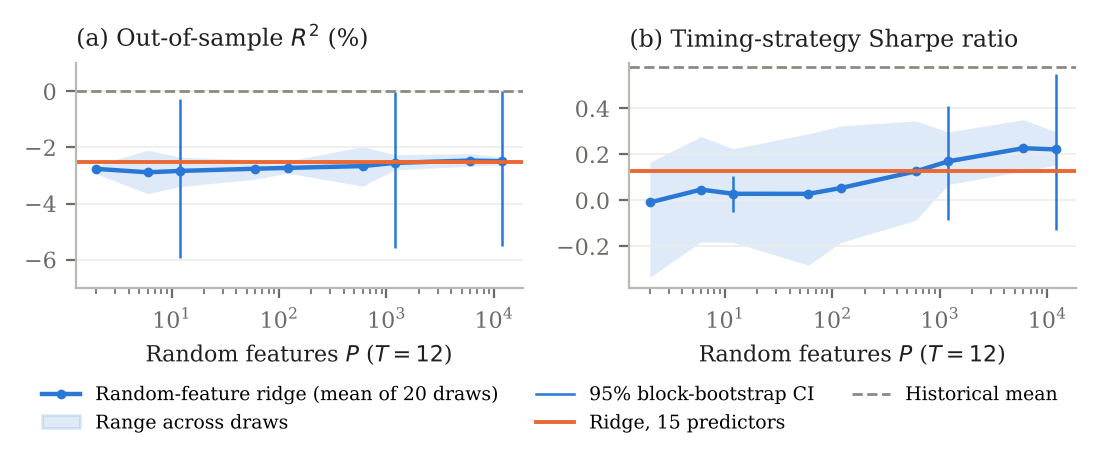

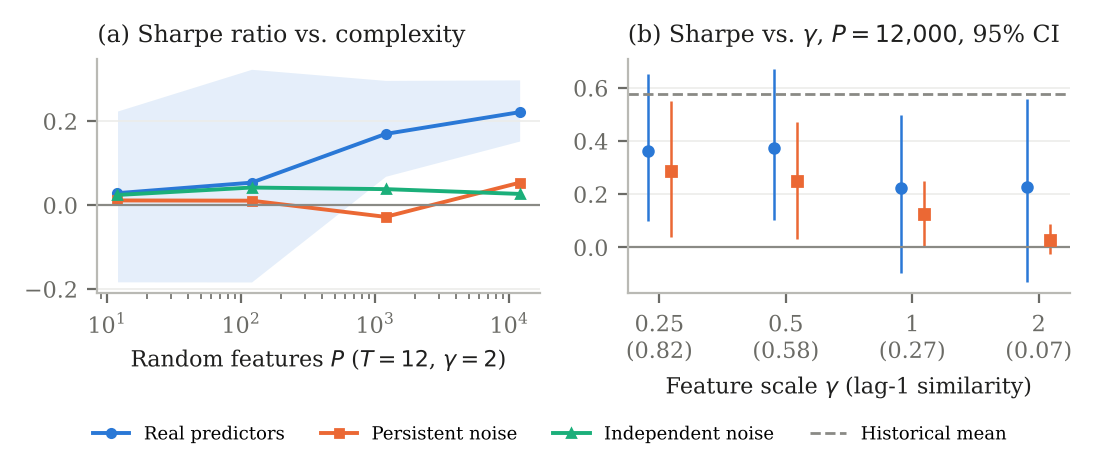

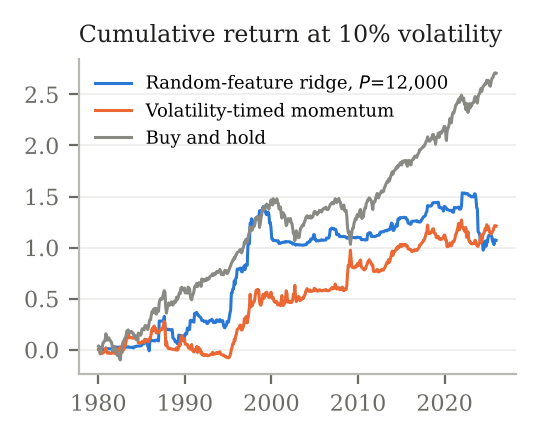

In [9]:
import json
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

indir, outdir = OUT, FIG
R = json.load(open(f"{indir}/results.json"))
FZ = np.load(f"{indir}/forecasts.npz")
y, tym, test = FZ["y"], FZ["tym"], FZ["test"]
hm = FZ["hm"]

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
INK, MUTED = "#1f1f1e", "#6b6b66"
plt.rcParams.update({"font.size": 8, "font.family": "serif", "axes.edgecolor": "#b9b9b4",
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": INK,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 8.5, "axes.titlelocation": "left"})
S = R["scores"]


def per_draw(key, metric):
    F = np.atleast_2d(FZ[key])[:, test]
    yt, ht = y[test], hm[test]
    if metric == "r2":
        return np.array([100 * (1 - np.sum((yt - f) ** 2) / np.sum((yt - ht) ** 2)) for f in F])
    r = F * yt
    return np.sqrt(12) * r.mean(1) / r.std(1, ddof=1)


# ---------------- Figure 1: complexity curve at T = 12
Ps = [2, 6, 12, 60, 120, 600, 1200, 6000, 12000]
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.25), dpi=300)
for ax, metric, title in ((axes[0], "r2", r"(a) Out-of-sample $R^2$ (%)"),
                          (axes[1], "sr", "(b) Timing-strategy Sharpe ratio")):
    D = np.array([per_draw(f"rff_T12_P{P}", metric) for P in Ps])
    ax.fill_between(Ps, D.min(1), D.max(1), color=BLUE, alpha=0.15, lw=0)
    ax.plot(Ps, D.mean(1), color=BLUE, lw=1.6, marker="o", ms=2.5)
    for P in (12, 1200, 12000):
        ci = np.array(S[f"rff_T12_P{P}"]["test"]["r2_ci" if metric == "r2" else "sr_ci"])
        ci = ci * (100 if metric == "r2" else 1)
        ax.vlines(P, *ci, color=BLUE, lw=0.9)
    rv = S["ridge_T12"]["test"]["r2" if metric == "r2" else "sr"] * (100 if metric == "r2" else 1)
    hv = 0.0 if metric == "r2" else S["hm"]["test"]["sr"]
    ax.axhline(hv, color=GRAY, lw=1, ls="--")
    ax.axhline(rv, color=ORANGE, lw=1.4)
    ax.set_xscale("log")
    ax.set_xlabel("Random features $P$ ($T=12$)")
    ax.set_title(title, color=INK)
    ax.grid(axis="y", color="#ececea", lw=0.6)
axes[0].set_ylim(-7, 1)
handles = [Line2D([], [], color=BLUE, lw=1.6, marker="o", ms=2.5, label="Random-feature ridge (mean of 20 draws)"),
           Patch(color=BLUE, alpha=0.15, label="Range across draws"),
           Line2D([], [], color=BLUE, lw=0.9, label="95% block-bootstrap CI"),
           Line2D([], [], color=ORANGE, lw=1.4, label="Ridge, 15 predictors"),
           Line2D([], [], color=GRAY, lw=1, ls="--", label="Historical mean")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=6.8)
fig.tight_layout(rect=(0, 0.13, 1, 1), w_pad=1.5)
fig.savefig(f"{outdir}/fig_complexity.pdf")
fig.savefig(f"{outdir}/fig_complexity.png", dpi=200, facecolor="white")
plt.close(fig)

# ---------------- Figure 2: placebo vs P (gamma = 2) and vs gamma (P = 12,000)
GJ = json.load(open(f"{indir}/gamma.json"))
Psub = [12, 120, 1200, 12000]
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.3), dpi=300)
ax = axes[0]
series = [("rff_T12_P{}", "Real predictors", BLUE, "o"),
          ("placebo_ar1_P{}", "Persistent noise", ORANGE, "s"),
          ("placebo_iid_P{}", "Independent noise", AQUA, "^")]
for tmpl, lab, col, mk in series:
    D = np.array([per_draw(tmpl.format(P), "sr") for P in Psub])
    if col == BLUE:
        ax.fill_between(Psub, D.min(1), D.max(1), color=col, alpha=0.12, lw=0)
    ax.plot(Psub, D.mean(1), color=col, lw=1.4, marker=mk, ms=3, label=lab)
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xscale("log")
ax.set_xlabel(r"Random features $P$ ($T=12$, $\gamma=2$)")
ax.set_title("(a) Sharpe ratio vs. complexity", color=INK)
ax.grid(axis="y", color="#ececea", lw=0.6)
ax = axes[1]
gs = [0.25, 0.5, 1.0, 2.0]
x = np.arange(len(gs))
for off, name, lab, col, mk in ((-0.09, "real", "Real predictors", BLUE, "o"),
                                (0.09, "ar1", "Persistent noise", ORANGE, "s")):
    v = np.array([GJ[f"{name}_g{g}"]["test"]["sr"] for g in gs])
    ci = np.array([GJ[f"{name}_g{g}"]["test"]["sr_ci"] for g in gs])
    ax.errorbar(x + off, v, yerr=[v - ci[:, 0], ci[:, 1] - v], fmt=mk, color=col, ms=3.5,
                elinewidth=0.9, capsize=0)
ax.axhline(S["hm"]["test"]["sr"], color=GRAY, lw=1, ls="--")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"{g:g}\n({GJ[f'sim_g{g}']['lag1']:.2f})" for g in gs])
ax.set_xlabel(r"Feature scale $\gamma$ (lag-1 similarity)")
ax.set_title(r"(b) Sharpe vs. $\gamma$, $P=12{,}000$, 95% CI", color=INK)
ax.grid(axis="y", color="#ececea", lw=0.6)
handles = [Line2D([], [], color=BLUE, lw=1.4, marker="o", ms=3, label="Real predictors"),
           Line2D([], [], color=ORANGE, lw=1.4, marker="s", ms=3, label="Persistent noise"),
           Line2D([], [], color=AQUA, lw=1.4, marker="^", ms=3, label="Independent noise"),
           Line2D([], [], color=GRAY, lw=1, ls="--", label="Historical mean")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=6.5)
fig.tight_layout(rect=(0, 0.08, 1, 1), w_pad=1.5)
fig.savefig(f"{outdir}/fig_placebo.pdf")
fig.savefig(f"{outdir}/fig_placebo.png", dpi=200, facecolor="white")
plt.close(fig)

# ---------------- Figure 3: cumulative strategy returns, scaled to 10% vol
fig, ax = plt.subplots(figsize=(2.7, 2.2), dpi=300)
yt = y[test]
dates = tym[test]
yr = dates // 100 + (dates % 100 - 0.5) / 12


def scaled_cum(r):
    r = r * 0.10 / (r.std(ddof=1) * np.sqrt(12))
    return np.cumsum(r)


rff = (np.atleast_2d(FZ["rff_T12_P12000"])[:, test] * yt).mean(0)   # equal weight over draws
for r, lab, col in ((rff, "Random-feature ridge, $P$=12,000", BLUE),
                    (FZ["vtm"][test] * yt, "Volatility-timed momentum", ORANGE),
                    (yt, "Buy and hold", GRAY)):
    ax.plot(yr, scaled_cum(r), color=col, lw=1.1, label=lab)
ax.set_title("Cumulative return at 10% volatility", color=INK)
ax.grid(axis="y", color="#ececea", lw=0.6)
ax.legend(frameon=False, fontsize=6.5, loc="upper left")
fig.tight_layout()
fig.savefig(f"{outdir}/fig_cumret.pdf")
fig.savefig(f"{outdir}/fig_cumret.png", dpi=200, facecolor="white")
plt.close(fig)
print("figures saved")

from IPython.display import Image, display
for f in ('fig_complexity', 'fig_placebo', 'fig_cumret'):
    display(Image(f'{FIG}/{f}.png'))

## 8. Summary table (test period 1980–2025)

In [10]:
import json, pandas as pd
R = json.load(open(f'{OUT}/results.json'))
rows = []
names = {'hm': 'Historical mean', 'ols': 'OLS (expanding)', 'lasso': 'Lasso (expanding)',
         'ridge_T12': 'Ridge, T=12', 'rff_T12_P12': 'Random features, P=12',
         'rff_T12_P1200': 'Random features, P=1,200', 'rff_T12_P12000': 'Random features, P=12,000'}
for k, lab in names.items():
    t = R['scores'][k]['test']
    rows.append({'Model': lab, 'R2_OOS (%)': 100 * t['r2'],
                 'R2 95% CI': f"[{100*t['r2_ci'][0]:.2f}, {100*t['r2_ci'][1]:.2f}]",
                 'Sharpe': t['sr'], 'Sharpe 95% CI': f"[{t['sr_ci'][0]:.2f}, {t['sr_ci'][1]:.2f}]"})
if os.path.exists(f'{OUT}/mlp_results.json'):
    M = json.load(open(f'{OUT}/mlp_results.json'))
    for k in ('mlp_T12', 'mlp_T120'):
        t = M[k]['test']
        rows.append({'Model': k.replace('mlp_T', 'MLP, T='), 'R2_OOS (%)': 100 * t['r2'],
                     'R2 95% CI': f"[{100*t['r2_ci'][0]:.2f}, {100*t['r2_ci'][1]:.2f}]",
                     'Sharpe': t['sr'], 'Sharpe 95% CI': f"[{t['sr_ci'][0]:.2f}, {t['sr_ci'][1]:.2f}]"})
print('Buy-and-hold Sharpe ratio:', round(R['market_sharpe']['test'], 2))
pd.DataFrame(rows).set_index('Model').round(3)

Buy-and-hold Sharpe ratio: 0.59


,R2_OOS (%),R2 95% CI,Sharpe,Sharpe 95% CI
Model,,,,
Historical mean,0.000,"[0.00, 0.00]",0.578,"[0.27, 0.91]"
OLS (expanding),-10.608,"[-17.77, -4.13]",0.070,"[-0.16, 0.44]"
Lasso (expanding),-0.031,"[-0.16, 0.08]",0.578,"[0.27, 0.92]"
"Ridge, T=12",-2.509,"[-5.44, 0.13]",0.130,"[-0.07, 0.41]"
"Random features, P=12",-2.838,"[-5.95, -0.28]",0.029,"[-0.05, 0.10]"
"Random features, P=1,200",-2.550,"[-5.58, -0.01]",0.170,"[-0.08, 0.41]"
"Random features, P=12,000",-2.491,"[-5.52, 0.02]",0.222,"[-0.13, 0.55]"
"MLP, T=12",-31.918,"[-44.35, -19.83]",0.095,"[-0.21, 0.35]"
"MLP, T=120",-24.405,"[-37.57, -12.75]",0.197,"[-0.13, 0.56]"
